## This notebook creates a table with monthly seascape class and cruise metadata, and renders data visualizations and seascape maps.

In [1]:
# Load libraries
import pandas as pd
import numpy as np
import xarray as xr
from pathlib import Path
import matplotlib.pyplot as plt
import requests
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm
from scipy.spatial import KDTree
from scipy.stats import mode as sp_mode

In [2]:
# Load Argo data
# Define the path to the data file
argo_file = Path('Gulf_BGCArgo_13May2026.csv').expanduser()

# Load the data into a pandas DataFrame
argo_df = pd.read_csv(argo_file)

# Display the first few rows of the DataFrame to verify it loaded correctly
argo_df.head()

# Print few rows of the DataFrame to verify it loaded correctly
print(argo_df.tail(1))

     CYCLE_NUMBER     WMOID  LATITUDE  LONGITUDE         JULD       TIME
495           110  F7901009   27.5145   -85.8639  27890.15823  5/12/2026


In [3]:
# Convert JULD (Julian Day) to datetime
# JULD is typically days since 1950-01-01 in Argo data
argo_df['datetime'] = pd.to_datetime(argo_df['JULD'], unit='D', origin='1950-01-01')

# Display the result
print(argo_df.tail(1))

     CYCLE_NUMBER     WMOID  LATITUDE  LONGITUDE         JULD       TIME  \
495           110  F7901009   27.5145   -85.8639  27890.15823  5/12/2026   

                         datetime  
495 2026-05-12 03:47:51.072000077  


In [4]:
# Change this variable to 'SEASCAPE_MONTH' or 'SEASCAPE_8DAY' as needed
dataset_type = 'SEASCAPE_MONTH' 

# Define Domain Limits and Dates 
n_lat = 31
s_lat = 18
e_lon = -78
w_lon = -98
start_date = '2021-08-15T12:00:00Z'
end_date = '2026-05-15T12:00:00Z'

# Build the Request for the MONTHLY Product 
print(f"Configuring request for: {dataset_type}")

base_url = f"https://cwcgom.aoml.noaa.gov/thredds/ncss/{dataset_type}/SEASCAPES.nc"

params = {
    'var': ['CLASS', 'P'],
    'north': n_lat,
    'west': w_lon,
    'east': e_lon,
    'south': s_lat,
    'disableProjSubset': 'on',
    'horizStride': 1,
    'time_start': start_date,
    'time_end': end_date,
    'timeStride': 1,
    'addLatLon': 'true',
    'accept': 'netcdf',
}

req = requests.Request('GET', base_url, params=params).prepare()
url = req.url

print("Requesting data from URL:")
print(url)

# Download the Data Manually and Then Open ---
output_filename = 'seascape_data_argo_monthly.nc'

try:
    # Download the file using requests
    print(f"\nDownloading data to '{output_filename}'...")
    with requests.get(url, stream=True) as r:
        r.raise_for_status()  # This will raise an error for bad status codes
        with open(output_filename, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    print("Download complete.")

    # Open the local file with xarray
    ds = xr.open_dataset(output_filename)
    print("\nSuccessfully loaded dataset from local file:")
    print(ds)

    # Analyze Unique Classes ---
    class_data = ds['CLASS'].values
    unique_classes_with_nan = np.unique(class_data)
    unique_classes = unique_classes_with_nan[~np.isnan(unique_classes_with_nan)]

    print("\nUnique classes present in CLASS:")
    print(unique_classes.astype(int))

except Exception as err:
    print(f"\nAn error occurred: {err}")

Configuring request for: SEASCAPE_MONTH
Requesting data from URL:
https://cwcgom.aoml.noaa.gov/thredds/ncss/SEASCAPE_MONTH/SEASCAPES.nc?var=CLASS&var=P&north=31&west=-98&east=-78&south=18&disableProjSubset=on&horizStride=1&time_start=2021-08-15T12%3A00%3A00Z&time_end=2026-05-15T12%3A00%3A00Z&timeStride=1&addLatLon=true&accept=netcdf

Download complete.

Successfully loaded dataset from local file:
<xarray.Dataset> Size: 49MB
Dimensions:  (time: 58, lat: 261, lon: 401)
Coordinates:
  * time     (time) datetime64[ns] 464B 2021-08-15T12:00:00 ... 2026-05-15T12...
  * lat      (lat) float32 1kB 18.02 18.08 18.12 18.17 ... 30.92 30.98 31.02
  * lon      (lon) float32 2kB -97.97 -97.93 -97.88 ... -78.07 -78.03 -77.97
Data variables:
    CLASS    (time, lat, lon) float32 24MB ...
    P        (time, lat, lon) float32 24MB ...
Attributes: (12/32)
    Conventions:                CF-1.6,ACDD-1.3
    title:                      Global Seascapes: Prototype
    institution:                NOAA Coas

In [5]:
# Create TIMEVEC DataFrame.
# Access the time coordinate from the xarray dataset
time_coordinate = ds['time']

# Create a dictionary with the year, month, day, and full datetime
time_data = {
    'year': time_coordinate.dt.year.values,
    'month': time_coordinate.dt.month.values,
    'day': time_coordinate.dt.day.values,
    'datetime': time_coordinate.values
}

# Convert the dictionary into a pandas DataFrame
TIMEVEC = pd.DataFrame(time_data)

print("Created TIMEVEC DataFrame:")
print(TIMEVEC)

Created TIMEVEC DataFrame:
    year  month  day            datetime
0   2021      8   15 2021-08-15 12:00:00
1   2021      9   15 2021-09-15 12:00:00
2   2021     10   15 2021-10-15 12:00:00
3   2021     11   15 2021-11-15 12:00:00
4   2021     12   15 2021-12-15 12:00:00
5   2022      1   15 2022-01-15 12:00:00
6   2022      2   15 2022-02-15 12:00:00
7   2022      3   15 2022-03-15 12:00:00
8   2022      4   15 2022-04-15 12:00:00
9   2022      5   15 2022-05-15 12:00:00
10  2022      6   15 2022-06-15 12:00:00
11  2022      7   15 2022-07-15 12:00:00
12  2022      8   15 2022-08-15 12:00:00
13  2022      9   15 2022-09-15 12:00:00
14  2022     10   15 2022-10-15 12:00:00
15  2022     11   15 2022-11-15 12:00:00
16  2022     12   15 2022-12-15 12:00:00
17  2023      1   15 2023-01-15 12:00:00
18  2023      2   15 2023-02-15 12:00:00
19  2023      3   15 2023-03-15 12:00:00
20  2023      4   15 2023-04-15 12:00:00
21  2023      5   15 2023-05-15 12:00:00
22  2023      6   15 2023-06-1

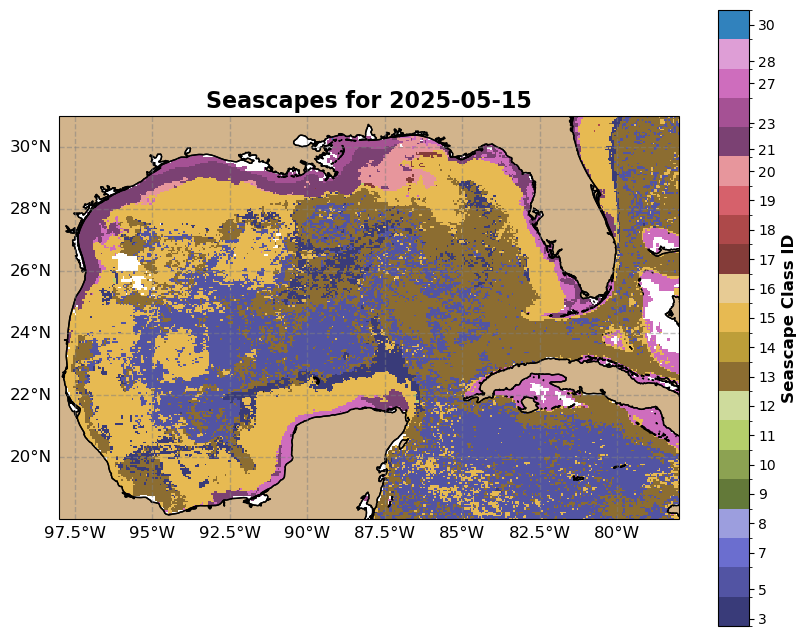

In [6]:
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, BoundaryNorm

#  Map Seascape Data for a Single Time Step as a test

# Select the Data for a Single Time Step 
seascape_selected = ds.isel(time=45)

# Find every unique class across the ENTIRE dataset to ensure absolute consistency
all_values = ds['CLASS'].values
global_classes = np.unique(all_values[~np.isnan(all_values)]).astype(int)
num_global_classes = len(global_classes)

# Select a base color palette. If you have more than 20 classes, we stitch 
# tab20b and tab20c together so colors never repeat.
if num_global_classes <= 20:
    colors = plt.get_cmap('tab20b')(np.linspace(0, 1, num_global_classes))
else:
    combined_palette = np.vstack([
        plt.get_cmap('tab20b')(np.linspace(0, 1, 20)),
        plt.get_cmap('tab20c')(np.linspace(0, 1, 20))
    ])
    colors = combined_palette[:num_global_classes]

# Create the global, unchanging colormap and normalization bounds
common_cmap = ListedColormap(colors)
common_bounds = np.append(global_classes, global_classes[-1] + 1) - 0.5
common_norm = BoundaryNorm(common_bounds, ncolors=common_cmap.N)

# --- Set Up the Map ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())

# --- Plot the Seascape Data ---
# Pass the normalization object ('norm') to ensure correct color mapping
mesh = ax.pcolormesh(
    seascape_selected['lon'], 
    seascape_selected['lat'], 
    seascape_selected['CLASS'],
    cmap=common_cmap,
    norm=common_norm, # Apply the normalization rule
    transform=ccrs.PlateCarree()
)

# --- Add Map Features ---
ax.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='tan')
ax.add_feature(cfeature.COASTLINE)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}

# --- Add Colorbar and Title ---
# The colorbar will automatically use the correct normalization from 'mesh'
cbar = plt.colorbar(mesh, ax=ax, ticks=unique_classes)
cbar.set_label('Seascape Class ID', fontsize=12, weight='bold')

# Get the date from the selected data
seascape_date = pd.to_datetime(seascape_selected.time.values).strftime('%Y-%m-%d')

# Set the title using the extracted date
ax.set_title(f'Seascapes for {seascape_date}', fontsize=16, weight='bold')

plt.show()

In [ ]:
# First, let's define the parameters and prepare the data structures needed for the analysis.

# --- Parameters ---
N_PIXELS = 3  # Radius in pixels to search around each station
PIX_RESOLUTION_DEG = 0.0416 # Approximate resolution of 4-km seascapes in degrees
SEARCH_RADIUS_DEG = N_PIXELS * PIX_RESOLUTION_DEG

# Prepare the seascape grid coordinates for efficient searching
# Flatten the lat/lon grid into a list of (lat, lon) points
lon_grid, lat_grid = np.meshgrid(ds['lon'].values, ds['lat'].values)
grid_points = np.vstack([lat_grid.ravel(), lon_grid.ravel()]).T

# Create a KD-Tree for fast nearest-neighbor searches. This is much faster
# than calculating the distance to every single grid point.
kdtree = KDTree(grid_points)

### USE THE NEXT CELL FOR MONTHLY SEASCAPE EXTRACTIONS

In [ ]:
# FOR MONTHLY EXTRACTIONS: This loop iterates through each month, creates the map,
#  and performs the extraction and analysis.

# List to store the final results
all_sites_summary_monthly = []

# Loop through each time step (month) in the seascape data
for i, t_row in TIMEVEC.iterrows():
    current_year = t_row['year']
    current_month = t_row['month']

    # --- Find corresponding argo profiles for this month and year ---
    monthly_argo_df = argo_df.loc[
        (argo_df['datetime'].dt.year == current_year) &
        (argo_df['datetime'].dt.month == current_month)
    ].copy()

    if monthly_argo_df.empty:
        print(f"No argo profiles for {current_year}-{current_month:02d}. Skipping.")
        continue

    print(f"Processing {len(monthly_argo_df)} argo profiles for {current_year}-{current_month:02d}...")

    seascape_monthly = ds.isel(time=i)
    
    # # --- A. Create the Map ---
    # if not monthly_argo_df.empty:
    #     fig = plt.figure(figsize=(10, 8))
    #     ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    #     ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())

    #     # Use BoundaryNorm for correct categorical coloring
    #     if unique_classes.size > 0:
    #         common_bounds = np.append(unique_classes, unique_classes[-1] + 1) - 0.5
    #         common_norm = BoundaryNorm(common_bounds, ncolors=common_cmap.N)
    #         mesh = ax.pcolormesh(
    #             seascape_monthly['lon'], seascape_monthly['lat'], seascape_monthly['CLASS'],
    #             cmap=common_cmap, norm=common_norm, transform=ccrs.PlateCarree()
    #         )
    #         cbar = plt.colorbar(mesh, ax=ax, ticks=unique_classes, pad=0.05, aspect=25)
    #         cbar.set_label('Seascape Class ID', fontsize=12)


    # mesh = ax.pcolormesh(
    #     seascape_monthly['lon'], seascape_monthly['lat'], seascape_monthly['CLASS'],
    #     cmap=common_cmap, norm=common_norm, transform=ccrs.PlateCarree()
    # )

    # ax.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='tan')
    # ax.add_feature(cfeature.COASTLINE)
    # ax.gridlines(draw_labels=True, linestyle='--')
    # ax.scatter(
    #     monthly_argo_df['LONGITUDE'], monthly_argo_df['LATITUDE'],
    #     s=50, c='black', marker='*', transform=ccrs.PlateCarree(),
    #     label='Cruise Stations'
    # )
    # ax.set_title(f"Seascapes: {current_year}-{current_month:02d}", fontsize=16)
    # plt.savefig(f"{current_year}-{current_month:02d}_map.png", dpi=150, bbox_inches='tight')
    # plt.close(fig)

    # --- B. Extract Surrounding Seascape Pixels ---
    station_points = monthly_argo_df[['LATITUDE', 'LONGITUDE']].values
    nearby_indices_list = kdtree.query_ball_point(station_points, r=SEARCH_RADIUS_DEG)
    monthly_argo_df['nearby_grid_indices'] = nearby_indices_list
    
    # --- C. Calculate Modal Seascape Class ---
    site_summaries = []
    for idx, station in monthly_argo_df.iterrows():
        flat_indices = station['nearby_grid_indices']
        
        # Check if any grid cells were found nearby
        if not flat_indices:
            # Case 1: No grid cells within search radius. Assign NaN and record.
            modal_class = np.nan
            mean_prob_of_modal = np.nan
        else:
            # Grid cells were found, now check if they are valid (not NaN)
            rows, cols = np.unravel_index(flat_indices, seascape_monthly['CLASS'].shape)
            nearby_classes = seascape_monthly['CLASS'].values[rows, cols]
            nearby_probs = seascape_monthly['P'].values[rows, cols]
            
            valid_mask = ~np.isnan(nearby_classes)
            valid_classes = nearby_classes[valid_mask]
            
            if valid_classes.size > 0:
                # Case 2: Valid (non-NaN) grid cells exist. Compute mode.
                modal_class = sp_mode(valid_classes, keepdims=False).mode
                valid_probs = nearby_probs[valid_mask]
                probs_of_modal_class = valid_probs[valid_classes == modal_class]
                mean_prob_of_modal = np.mean(probs_of_modal_class)
            else:
                # Case 3: All nearby grid cells were NaN. Assign NaN and record.
                modal_class = np.nan
                mean_prob_of_modal = np.nan

        # Format the window dates into a clean string identifier
        window_start = pd.Timestamp(year=current_year, month=current_month, day=1)
        window_end = window_start + pd.offsets.MonthEnd(0)
        window_start_str = window_start.strftime('%Y-%m-%d')
        window_end_str = window_end.strftime('%Y-%m-%d')
        time_window_label = f"{window_start_str}_to_{window_end_str}"

        # Append the result for the station, covering all cases to ensure no station is skipped
        site_summaries.append({
            'CYCLE_NUMBER': station['CYCLE_NUMBER'], 
            'WMOID': station['WMOID'],
            'LATITUDE': station['LATITUDE'],
            'LONGITUDE': station['LONGITUDE'],
            'JULD': station['JULD'], 
            'TIME': station['TIME'], 
            'datetime': station['datetime'],
            'MONTH_WINDOW': time_window_label, 
            'modal_seascape_class': modal_class, 
            'mean_seascape_prob': mean_prob_of_modal
        })

    all_sites_summary_monthly.extend(site_summaries)

# Convert the final list of results into a pandas DataFrame
conc_class_per_site_monthly = pd.DataFrame(all_sites_summary_monthly)

# Define the output filename
output_filename = "seascape_argo_summary_monthly.tsv"

# Save the DataFrame to a .tsv file
# sep='\t' specifies a tab separator, and index=False prevents writing the row numbers
conc_class_per_site_monthly.to_csv(output_filename, sep='\t', index=False)

print("\n--- Analysis Complete ---")
print("Final summary of modal seascape classes for Argo profiles:")
print(conc_class_per_site_monthly.tail(1))
print(f"\nResults saved to '{output_filename}'")

### USE THE NEXT CELL FOR 8-DAY SEASCAPE EXTRACTIONS

In [ ]:
# FOR 8-DAY EXTRACTIONS: Loop through each 8-day time window
# Prepare for Storing Results ---
all_sites_summary_8day = []

# We stop at -1 because each window is defined by a start (i) and end (i+1) time
for i in range(len(ds.time) - 1):
    start_date = ds.time.values[i]
    end_date = ds.time.values[i+1]

    # --- Find corresponding argo data within the 8-day window ---
    argo_in_window_df = argo_df[
        (argo_df['datetime'] >= start_date) & 
        (argo_df['datetime'] < end_date) 
    ].copy()

    print(f"Processing {len(argo_in_window_df)} window starting {pd.to_datetime(start_date).strftime('%Y-%m-%d')}...")

    # Select the seascape data for the current time step
    seascape_8day = ds.isel(time=i)
    
    # # --- A. Create the Map ---
    # if not argo_in_window_df.empty:
    #     fig = plt.figure(figsize=(10, 8))
    #     ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    #     ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())

    #     # Use BoundaryNorm for correct categorical coloring
    #     if unique_classes.size > 0:
    #         common_bounds = np.append(unique_classes, unique_classes[-1] + 1) - 0.5
    #         common_norm = BoundaryNorm(common_bounds, ncolors=common_cmap.N)
    #         mesh = ax.pcolormesh(seascape_8day['lon'], seascape_8day['lat'], seascape_8day['CLASS'], cmap=common_cmap, norm=common_norm, transform=ccrs.PlateCarree())
    #         cbar = plt.colorbar(mesh, ax=ax, ticks=unique_classes, pad=0.05, aspect=25)
    #         cbar.set_label('Seascape Class ID', fontsize=12)

    #     ax.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='tan')
    #     ax.add_feature(cfeature.COASTLINE)
    #     ax.gridlines(draw_labels=True, linestyle='--')
    #     ax.scatter(argo_in_window_df['LONGITUDE'], argo_in_window_df['LATITUDE'], s=50, c='black', marker='*', transform=ccrs.PlateCarree(), label='Argo Profiles')
    #     start_date_str = pd.to_datetime(start_date).strftime('%Y-%m-%d')
    #     end_date_str = pd.to_datetime(end_date).strftime('%Y-%m-%d')
    #     ax.set_title(f"Seascapes: {start_date_str}_to_{end_date_str}", fontsize=16)
    #     plt.savefig(f"{start_date_str}_to_{end_date_str}_map.png", dpi=150, bbox_inches='tight')
    #     plt.close(fig)

    # --- B. Extract Surrounding Seascape Pixels ---
    station_points = argo_in_window_df[['LATITUDE', 'LONGITUDE']].values
    nearby_indices_list = kdtree.query_ball_point(station_points, r=SEARCH_RADIUS_DEG)
    argo_in_window_df['nearby_grid_indices'] = nearby_indices_list
    
    # --- C. Calculate Modal Seascape Class ---
    site_summaries = []
    for idx, station in argo_in_window_df.iterrows():
        flat_indices = station['nearby_grid_indices']
        
        # Check if any grid cells were found nearby
        if not flat_indices:
            # Case 1: No grid cells within search radius. Assign NaN.
            modal_class = np.nan
            mean_prob_of_modal = np.nan
        else:
            # Grid cells were found, now check if they are valid (not NaN)
            rows, cols = np.unravel_index(flat_indices, seascape_8day['CLASS'].shape)
            nearby_classes = seascape_8day['CLASS'].values[rows, cols]
            nearby_probs = seascape_8day['P'].values[rows, cols]
            
            valid_mask = ~np.isnan(nearby_classes)
            valid_classes = nearby_classes[valid_mask]
            
            if valid_classes.size > 0:
                # Case 2: Valid (non-NaN) grid cells exist. Compute mode.
                modal_class = sp_mode(valid_classes, keepdims=False).mode
                valid_probs = nearby_probs[valid_mask]
                probs_of_modal_class = valid_probs[valid_classes == modal_class]
                mean_prob_of_modal = np.mean(probs_of_modal_class)
            else:
                # Case 3: All nearby grid cells were NaN. Assign NaN.
                modal_class = np.nan
                mean_prob_of_modal = np.nan

        # Format the window dates into a clean string identifier
        window_start_str = pd.to_datetime(start_date).strftime('%Y-%m-%d')
        window_end_str = pd.to_datetime(end_date).strftime('%Y-%m-%d')
        time_window_label = f"{window_start_str}_to_{window_end_str}"

        # Append the result for the station, covering all cases to ensure no station is skipped
        site_summaries.append({
            'CYCLE_NUMBER': station['CYCLE_NUMBER'], 
            'WMOID': station['WMOID'],
            'LATITUDE': station['LATITUDE'],
            'LONGITUDE': station['LONGITUDE'],
            'JULD': station['JULD'], 
            'TIME': station['TIME'], 
            'datetime': station['datetime'],
            '8_DAY_WINDOW': time_window_label, 
            'modal_seascape_class': modal_class, 
            'mean_seascape_prob': mean_prob_of_modal
        })
    all_sites_summary_8day.extend(site_summaries)

# Convert the final list of results into a pandas DataFrame
conc_class_per_site_8day = pd.DataFrame(all_sites_summary_8day)

# Define the output filename
output_filename = "seascape_argo_summary_8day.tsv"

# Save the DataFrame to a .tsv file
# sep='\t' specifies a tab separator, and index=False prevents writing the row numbers
# conc_class_per_site_8day.to_csv(output_filename, sep='\t', index=False)

print("\n--- 8-Day Analysis Complete ---")
print("Final summary of modal seascape classes for Argo profiles:")
print(conc_class_per_site_8day.tail(1))
print(f"\nResults saved to '{output_filename}'")

In [ ]:
windows_23 = conc_class_per_site_8day.loc[
    conc_class_per_site_8day['modal_seascape_class'] == 23,
    '8_DAY_WINDOW'
]

print(windows_23)

In [ ]:
hist_data = conc_class_per_site_8day['modal_seascape_class'].dropna().astype(int)
counts = hist_data.value_counts().reindex(np.sort(global_classes), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = common_cmap(np.linspace(0, 1, len(counts)))
ax.bar(counts.index, counts.values, color=bar_colors)
ax.set_xlabel('Modal Seascape Class')
ax.set_ylabel('Frequency')
ax.set_title('Frequency of Modal Seascape Classe - 8-day')
ax.set_xticks(counts.index)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

## Merge monthly and 8-day seascape tables into a single file. Monthly and 8-day cells must be run prior to this merge

In [ ]:
# Start with the 8-day data as the base
merged_df = conc_class_per_site_8day.copy()

# Directly append the two columns from the monthly data
# This assumes both tables have the exact same row order
merged_df['modal_class_monthly'] = conc_class_per_site_monthly['modal_seascape_class']
merged_df['mean_prob_monthly'] = conc_class_per_site_monthly['mean_seascape_prob']

# remane the columns for 8-day seascapes
merged_df.rename(columns={'modal_seascape_class': 'modal_class_8day'}, inplace=True)  
merged_df.rename(columns={'mean_seascape_prob': 'mean_prob_8day'}, inplace=True)

# --- Save the Final Merged File ---
output_filename = "seascape_station_summary_appended.tsv"
merged_df.to_csv(output_filename, sep='\t', index=False)

print("\n--- Appending Complete ---")
print("Final appended summary:")
print(merged_df.head())
print(f"\nResults saved to '{output_filename}'")

### Map Argo records color coded by seascape

Found local file topo_data.nc. Skipping download.


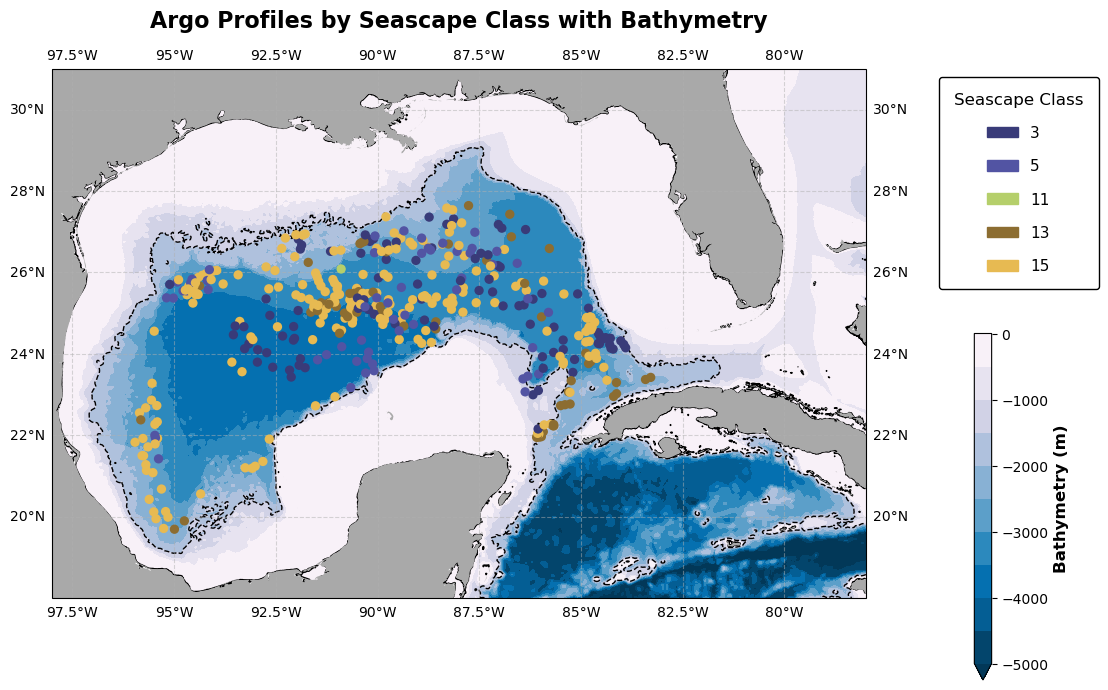

In [21]:
import pandas as pd
import numpy as np
import xarray as xr
import os
import requests
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

# --- 1. Define Domain Limits (From previous cells) ---
n_lat = 31
s_lat = 18
e_lon = -78
w_lon = -98

# --- 2. Load the Monthly Summary Data ---
df_argo = pd.read_csv('seascape_argo_summary_monthly.tsv', sep='\t')

# --- 3. Download Bathymetry Data (ETOPO) ---
topo_filename = 'topo_data.nc'
parent_topo_filename = os.path.join('..', topo_filename)

topo_url = (
    f"https://coastwatch.pfeg.noaa.gov/erddap/griddap/etopo180.nc?altitude"
    f"[({min(s_lat, n_lat)}):1:({max(s_lat, n_lat)})]"
    f"[({min(w_lon, e_lon)}):1:({max(w_lon, e_lon)})]"
)

# Check if the file already exists to avoid re-downloading
if os.path.exists(topo_filename):
    print(f"Found local file {topo_filename}. Skipping download.")
elif os.path.exists(parent_topo_filename):
    topo_filename = parent_topo_filename
    print(f"Found local file one directory up: {topo_filename}. Skipping download.")
else:
    print(f"Attempting to download bathymetry from: {topo_url}")
    try:
        r = requests.get(topo_url, timeout=120)
        if r.status_code == 200:
            with open(topo_filename, 'wb') as f:
                f.write(r.content)
            print("Bathymetry download complete.")
        else:
            print(f"Download failed with status {r.status_code}. Using fallback method...")
            topo_ds = None
    except Exception as e:
        print(f"Error occurred: {e}")
        topo_ds = None

# Subset bathymetry to our exact Gulf of Mexico bounding box
# Open topo file and subset to our bounding box, robust to variable/coord names
try:
    topo_ds = xr.open_dataset(topo_filename)
except Exception as e:
    print(f"Unable to open {topo_filename}: {e}")
    topo_ds = None

if topo_ds is None:
    bathy_sub = None
else:
    # Pick a sensible data variable (common names: 'bed','altitude','z',...)
    candidates = ['bed', 'altitude', 'elevation', 'z', 'depth', 'alt']
    var = next((v for v in candidates if v in topo_ds.data_vars), None)
    if var is None:
        var = list(topo_ds.data_vars)[0]  # fallback

    # Find latitude/longitude coordinate names
    lat_candidates = ['latitude', 'lat', 'y']
    lon_candidates = ['longitude', 'lon', 'x']
    lat_name = next((n for n in lat_candidates if n in topo_ds.coords), None)
    lon_name = next((n for n in lon_candidates if n in topo_ds.coords), None)
    if lat_name is None or lon_name is None:
        raise RuntimeError(f"Latitude/longitude coords not found in {topo_filename}. Available coords: {list(topo_ds.coords)}")

    # Subset and rename coords to match downstream code expecting 'latitude'/'longitude'
    bathy = topo_ds[var].sel({lat_name: slice(s_lat, n_lat), lon_name: slice(w_lon, e_lon)})
    if lat_name != 'latitude' or lon_name != 'longitude':
        bathy = bathy.rename({lat_name: 'latitude', lon_name: 'longitude'})

    bathy_sub = bathy

# --- 4. Set Up Dynamic Colors for Seascape Classes ---
# Find every unique class across the ENTIRE dataset to ensure absolute consistency
# (Assumes 'ds' is already loaded in memory from previous cells)
all_values = ds['CLASS'].values
global_classes = np.unique(all_values[~np.isnan(all_values)]).astype(int)
num_global_classes = len(global_classes)

# Select a base color palette. If you have more than 20 classes, we stitch 
# tab20b and tab20c together so colors never repeat.
if num_global_classes <= 20:
    colors = plt.get_cmap('tab20b')(np.linspace(0, 1, num_global_classes))
else:
    combined_palette = np.vstack([
        plt.get_cmap('tab20b')(np.linspace(0, 1, 20)),
        plt.get_cmap('tab20c')(np.linspace(0, 1, 20))
    ])
    colors = combined_palette[:num_global_classes]

# Create a dictionary for easy color lookup
seascape_palette = {cls: mcolors.to_hex(colors[i]) for i, cls in enumerate(global_classes)}

# Drop NaN seascape values so they don't plot as black points
df_argo_clean = df_argo.dropna(subset=['modal_seascape_class']).copy()

# Map the colors to a new column. Any unlisted classes will default to black
df_argo_clean['color'] = df_argo_clean['modal_seascape_class'].map(seascape_palette).fillna('black')

# --- 5. Create the Map ---
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())

# --- 6. Plot Bathymetry Contours ---
# Create filled contours from -5000m up to 0m using a reversed blue-purple colormap
if bathy_sub is not None:
    levels = np.arange(-5000, 1, 500)
    bathy_contour = ax.contourf(
        bathy_sub['longitude'], 
        bathy_sub['latitude'], 
        bathy_sub.values,
        levels=levels,
        cmap='PuBu_r', 
        extend='min',
        transform=ccrs.PlateCarree(),
        zorder=0
    )

    # Highlight the isobath with a black line
    ax.contour(
        bathy_sub['longitude'], 
        bathy_sub['latitude'], 
        bathy_sub.values,
        levels=[-1500, 0],
        colors='black',
        linewidths=1,
        transform=ccrs.PlateCarree(),
        zorder=1
    )

ax.add_feature(cfeature.LAND, zorder=2, edgecolor='none', facecolor='#A9A9A9') # Gray landmass
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, zorder=3)

# --- 7. Plot Argo Locations ---
scatter = ax.scatter(
    df_argo_clean['LONGITUDE'], 
    df_argo_clean['LATITUDE'], 
    c=df_argo_clean['color'], 
    s=45, 
    edgecolors='none', 
    transform=ccrs.PlateCarree(),
    zorder=4
)

# --- 8. Build Legends & Colorbars ---
# Custom Seascape Class Legend
# Filter to show only the classes actually present in the plotted Argo records
unique_argo_classes = np.sort(df_argo_clean['modal_seascape_class'].unique()).astype(int)
legend_patches = [
    mpatches.Circle((0, 0), radius=5, color=seascape_palette[cls], label=str(cls)) 
    for cls in unique_argo_classes if cls in seascape_palette
]

# Push legend to the top-right corner to avoid colorbar collision
leg = ax.legend(
    handles=legend_patches, 
    title='Seascape Class', 
    loc='upper left', 
    bbox_to_anchor=(1.08, 1.0), # Shifted up to y=1.0
    fontsize=11, 
    title_fontsize=12,
    framealpha=1,
    edgecolor='black',
    borderpad=1,
    labelspacing=1.2,
    ncol=2 if len(unique_argo_classes) > 10 else 1 
)

# Dynamically anchor the colorbar to the bottom-right half of the axes
if bathy_sub is not None:
    cbar = plt.colorbar(bathy_contour, ax=ax, orientation='vertical', shrink=0.5, pad=0.1, anchor=(0.0, 0.0))
    cbar.set_label('Bathymetry (m)', fontsize=12, weight='bold')
    cbar.set_ticks([-5000, -4000, -3000, -2000, -1000, 0])

ax.set_title('Argo Profiles by Seascape Class with Bathymetry', fontsize=16, weight='bold', pad=15)
plt.show()

### Define Quadrants & Map Selected Date using monthly seascapes

Interpolating bathymetry and building spatial masks...


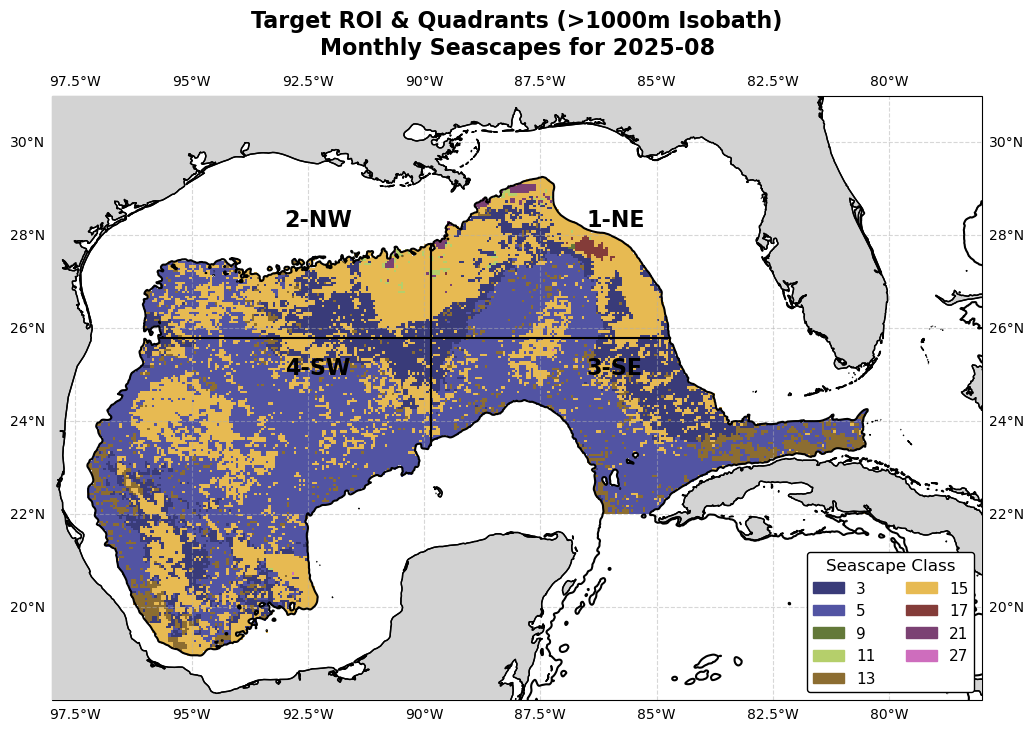

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm

# --- 1. Align Bathymetry to Seascape Grid ---
print("Interpolating bathymetry and building spatial masks...")
# Interpolate the bathymetry subset to exactly match the Seascape dataset's lat/lon grid
bathy_interp = bathy_sub.interp(latitude=ds.lat, longitude=ds.lon, method='nearest')
lon_grid, lat_grid = np.meshgrid(ds.lon.values, ds.lat.values)

# --- 2. Define the Region of Interest (ROI) Mask ---
# Condition 1: Depth strictly greater than 1000m (values <= -1000)
depth_mask = bathy_interp.values <= -1000

# Condition 2: Isolate the Gulf of Mexico (Cut off Caribbean and Straits of Florida)
gom_mask = np.ones_like(lat_grid, dtype=bool)
gom_mask &= ~((lat_grid < 22.0) & (lon_grid > -88)) # Sever Yucatan Channel / Caribbean
gom_mask &= ~(lon_grid > -80.0)                       # Sever Straits of Florida

# Combine to create the master valid mask
valid_mask = depth_mask & gom_mask

# --- 3. Define the 4 Quadrants ---
lat_c = 25.78
lon_c = -89.86

quadrant_masks = {
    '1-NE': valid_mask & (lat_grid >= lat_c) & (lon_grid >= lon_c),
    '2-NW': valid_mask & (lat_grid >= lat_c) & (lon_grid < lon_c),
    '3-SE': valid_mask & (lat_grid < lat_c) & (lon_grid >= lon_c),
    '4-SW': valid_mask & (lat_grid < lat_c) & (lon_grid < lon_c)
}

# --- 4. Define Dynamic Target Palette ---
# Find every unique class across the ENTIRE dataset to ensure absolute consistency
all_values = ds['CLASS'].values
global_classes = np.unique(all_values[~np.isnan(all_values)]).astype(int)
num_global_classes = len(global_classes)

# Select a base color palette. If you have more than 20 classes, we stitch 
# tab20b and tab20c together so colors never repeat.
if num_global_classes <= 20:
    colors = plt.get_cmap('tab20b')(np.linspace(0, 1, num_global_classes))
else:
    combined_palette = np.vstack([
        plt.get_cmap('tab20b')(np.linspace(0, 1, 20)),
        plt.get_cmap('tab20c')(np.linspace(0, 1, 20))
    ])
    colors = combined_palette[:num_global_classes]

# Create the global, unchanging colormap and normalization bounds
common_cmap = ListedColormap(colors)
common_bounds = np.append(global_classes, global_classes[-1] + 1) - 0.5
common_norm = BoundaryNorm(common_bounds, ncolors=common_cmap.N)

# Create a dictionary for easy color lookup (useful for legends)
seascape_palette = {cls: mcolors.to_hex(colors[i]) for i, cls in enumerate(global_classes)}

# --- 5. Extract a Single Month for Map Verification ---
target_month = '2025-08'
# Grab the monthly time step 
seascape_slice = ds['CLASS'].sel(time=target_month)
if 'time' in seascape_slice.dims:
    seascape_slice = seascape_slice.isel(time=0)

# Create a copy and apply the ROI mask (set areas outside deep GoM to NaN)
map_data = seascape_slice.values.copy()
map_data[~valid_mask] = np.nan 

# --- 6. Plot the Map ---
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([w_lon, e_lon, s_lat, n_lat], crs=ccrs.PlateCarree())

# Plot the seascapes within the >1000m ROI using the dynamic colormap
mesh = ax.pcolormesh(
    ds.lon.values, 
    ds.lat.values, 
    map_data, 
    cmap=common_cmap, 
    norm=common_norm, 
    transform=ccrs.PlateCarree(),
    zorder=2
)

# Plot the 1000m Isobath
ax.contour(
    bathy_sub['longitude'], 
    bathy_sub['latitude'], 
    bathy_sub.values,
    levels=[-1000],
    colors='black',
    linewidths=1.5,
    linestyles='solid',
    transform=ccrs.PlateCarree(),
    zorder=4
)

# Plot dividing lines for the quadrants STRICTLY INSIDE the 1000m isobath
# Find valid longitudes for the horizontal line at lat_c
lat_idx = np.abs(ds.lat.values - lat_c).argmin()
valid_lons = ds.lon.values[valid_mask[lat_idx, :]]
if len(valid_lons) > 0:
    ax.plot([valid_lons.min(), valid_lons.max()], [lat_c, lat_c], color='black', linewidth=1.5, linestyle='-', zorder=4, transform=ccrs.PlateCarree())

# Find valid latitudes for the vertical line at lon_c
lon_idx = np.abs(ds.lon.values - lon_c).argmin()
valid_lats = ds.lat.values[valid_mask[:, lon_idx]]
if len(valid_lats) > 0:
    ax.plot([lon_c, lon_c], [valid_lats.min(), valid_lats.max()], color='black', linewidth=1.5, linestyle='-', zorder=4, transform=ccrs.PlateCarree())

# Add quadrant labels
ax.text(-86.5, 28.2, '1-NE', fontsize=16, weight='bold', transform=ccrs.PlateCarree(), zorder=5)
ax.text(-93.0, 28.2, '2-NW', fontsize=16, weight='bold', transform=ccrs.PlateCarree(), zorder=5)
ax.text(-86.5, 25.0, '3-SE', fontsize=16, weight='bold', transform=ccrs.PlateCarree(), zorder=5)
ax.text(-93.0, 25.0, '4-SW', fontsize=16, weight='bold', transform=ccrs.PlateCarree(), zorder=5)

# Add map features
ax.add_feature(cfeature.LAND, zorder=3, edgecolor='black', facecolor='#d3d3d3')
ax.add_feature(cfeature.COASTLINE, zorder=3)
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, zorder=1)

# Add Legend (Filter to show only the classes actually present in this map slice)
unique_in_slice = np.unique(map_data[~np.isnan(map_data)]).astype(int)
legend_patches = [mpatches.Circle((0, 0), radius=5, color=seascape_palette[cls], label=str(int(cls))) for cls in unique_in_slice]
leg = ax.legend(handles=legend_patches, title='Seascape Class', loc='lower right', fontsize=11, title_fontsize=12, framealpha=1, edgecolor='black', ncol=2)

slice_time_str = pd.to_datetime(seascape_slice.time.values).strftime('%Y-%m')
ax.set_title(f"Target ROI & Quadrants (>1000m Isobath)\nMonthly Seascapes for {slice_time_str}", fontsize=16, weight='bold', pad=15)
plt.show()

### Extract Seascape Time Series & Plot Stacked Area Charts

Extracting Seascape time series for each quadrant...


/tmp/ipykernel_4070111/524880539.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ts_data = {q: pd.DataFrame(index=times, columns=global_classes).fillna(0.0) for q in quadrant_masks}
/tmp/ipykernel_4070111/524880539.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ts_data = {q: pd.DataFrame(index=times, columns=global_classes).fillna(0.0) for q in quadrant_masks}
/tmp/ipykernel_4070111/524880539.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_object

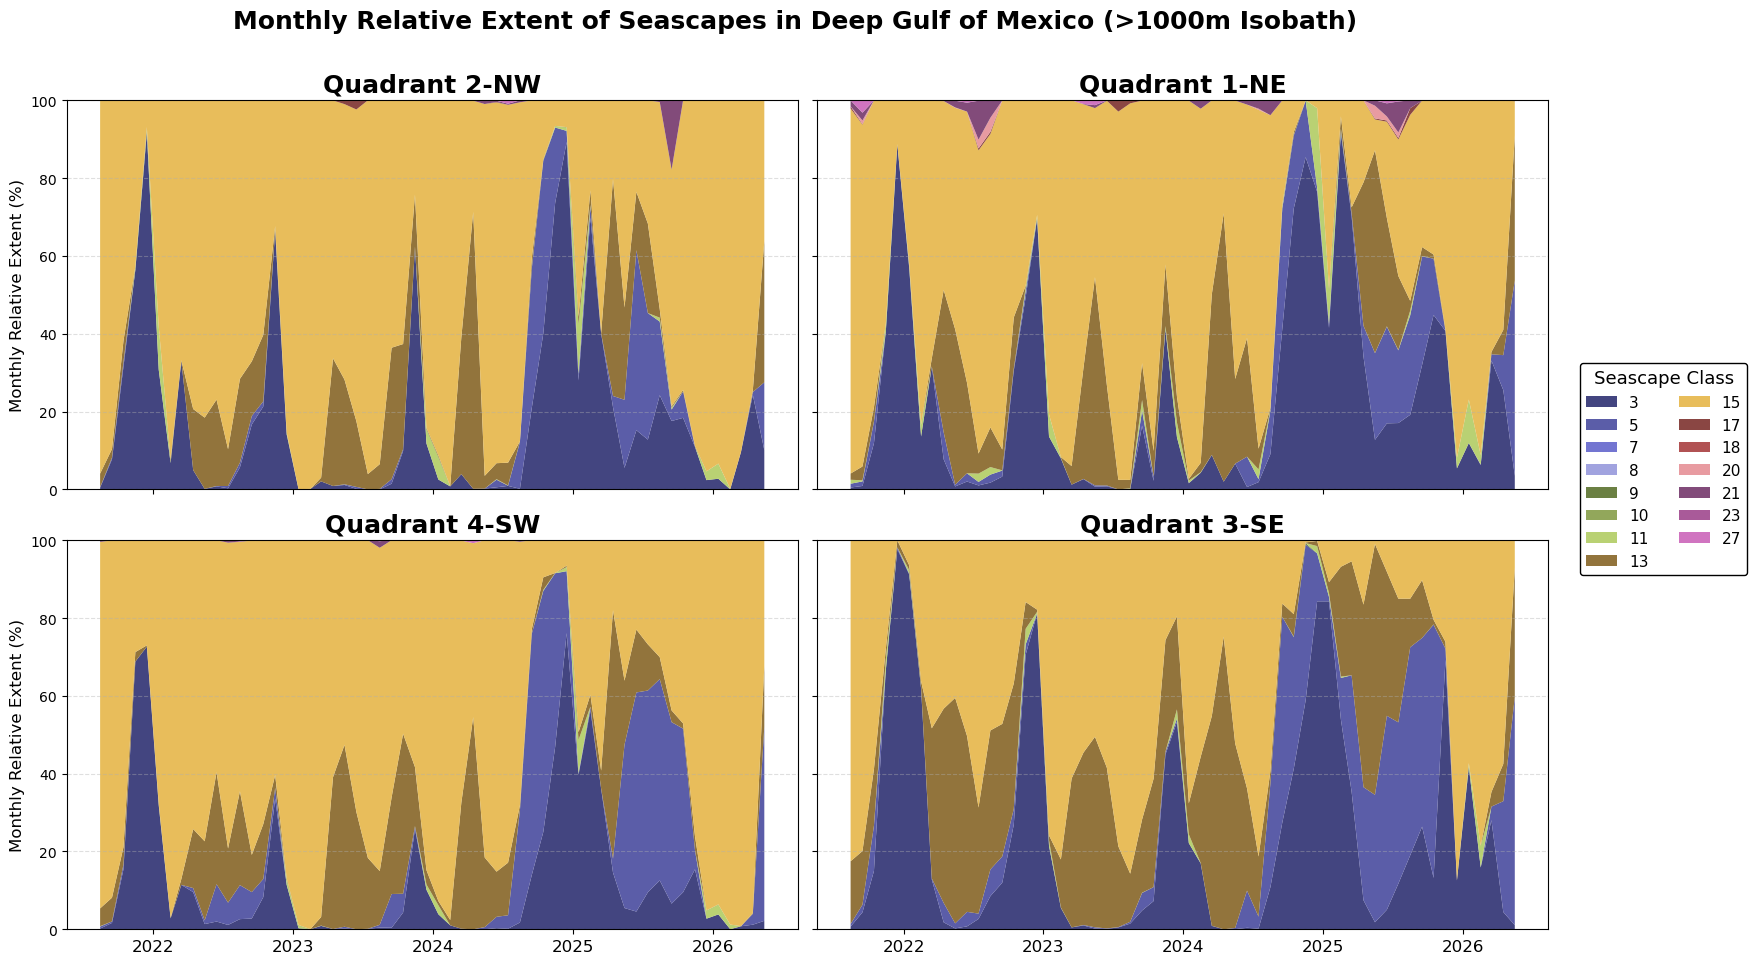

In [22]:
import matplotlib.dates as mdates

# --- 1. Extract the Seascape Time Series ---
print("Extracting Seascape time series for each quadrant...")
times = pd.to_datetime(ds.time.values)

# Initialize a dictionary of DataFrames to hold the relative percentages using the global_classes
ts_data = {q: pd.DataFrame(index=times, columns=global_classes).fillna(0.0) for q in quadrant_masks}

for i in range(len(times)):
    # Extract the 2D class array for the current monthly time step
    slice_class = ds.isel(time=i)['CLASS'].values
    
    for q, mask in quadrant_masks.items():
        # Apply the quadrant + bathymetry mask
        pixels = slice_class[mask]
        valid_pixels = pixels[~np.isnan(pixels)]
        total = len(valid_pixels)
        
        if total > 0:
            # Count pixels per class and convert to percentage relative to the whole valid quadrant
            counts = pd.Series(valid_pixels).value_counts()
            for c in global_classes:
                ts_data[q].loc[times[i], c] = (counts.get(c, 0) / total) * 100

# --- 2. Plot the Time Series ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

class_labels = [str(int(c)) for c in global_classes]

# Plot in geographical order: Top-Left (NW), Top-Right (NE), Bottom-Left (SW), Bottom-Right (SE)
plot_order = ['2-NW', '1-NE', '4-SW', '3-SE'] 

for idx, q in enumerate(plot_order):
    ax = axes[idx]
    df_q = ts_data[q]
    
    # Create the stacked area chart using the dynamic colors list generated in Cell 1
    ax.stackplot(df_q.index, df_q.T.values, labels=class_labels, colors=colors, alpha=0.95)
    
    ax.set_title(f"Quadrant {q}", fontsize=18, weight='bold')
    ax.set_ylim(0, 100)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    if idx % 2 == 0:
        ax.set_ylabel("Monthly Relative Extent (%)", fontsize=12)

# Format the X-axis to display years cleanly
for ax in axes[2:]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.tick_params(axis='x', labelsize=12)

# Build a unified legend outside the subplots
handles, leg_labels = axes[0].get_legend_handles_labels()

# Filter legend to only show classes that appear in ANY of the plotted quadrants
# This prevents the legend from being clogged with global classes not found in the GoM deep water
active_classes = set()
for q in plot_order:
    active_classes.update(ts_data[q].loc[:, ts_data[q].max() > 0].columns)
    
filtered_handles = [h for h, l in zip(handles, leg_labels) if int(l) in active_classes]
filtered_labels = [l for l in leg_labels if int(l) in active_classes]

leg = fig.legend(
    filtered_handles, filtered_labels, 
    title="Seascape Class", 
    loc='center right', 
    bbox_to_anchor=(1.10, 0.5), 
    fontsize=11, 
    title_fontsize=13,
    framealpha=1,
    edgecolor='black',
    ncol=1 if len(filtered_labels) <= 12 else 2 # Create two columns if there are many active classes
)

plt.suptitle("Monthly Relative Extent of Seascapes in Deep Gulf of Mexico (>1000m Isobath)", fontsize=18, weight='bold', y=0.96)
plt.tight_layout(rect=[0, 0, 0.98, 0.95]) # Leave space on the right for the legend
plt.show()